# Anàlisi en Teoria de l'Optimitat del corpus

In [15]:
from AIMeRiC.data.modules.analyse_OT import OT_eval
import pandas as pd
from AIMeRiC.corpus.modules.getUSB import getUSB

corpus = 'actual'
df = pd.read_csv(f'{getUSB()}/corpora/{corpus}/etiquetat/{corpus}.csv', sep=';', lineterminator='\n', encoding='utf-8')

ot_df = OT_eval(df)

# Totes les restriccions

,con,sum,%
0,extra_lapse,105,0.076448
1,extra_clash,1596,1.162003
2,lapse,5378,3.915573
3,strict_ws_hl,5517,4.016775
4,global_ws_hl,6526,4.751400
5,long_last,14518,10.570153
6,verse_bin,19155,13.946225
7,clash,21752,15.837028
8,interest,25603,18.640835
9,non_initial,33566,24.438474


<Axes: title={'center': 'Anàlisi de les restriccions'}, xlabel='con'>

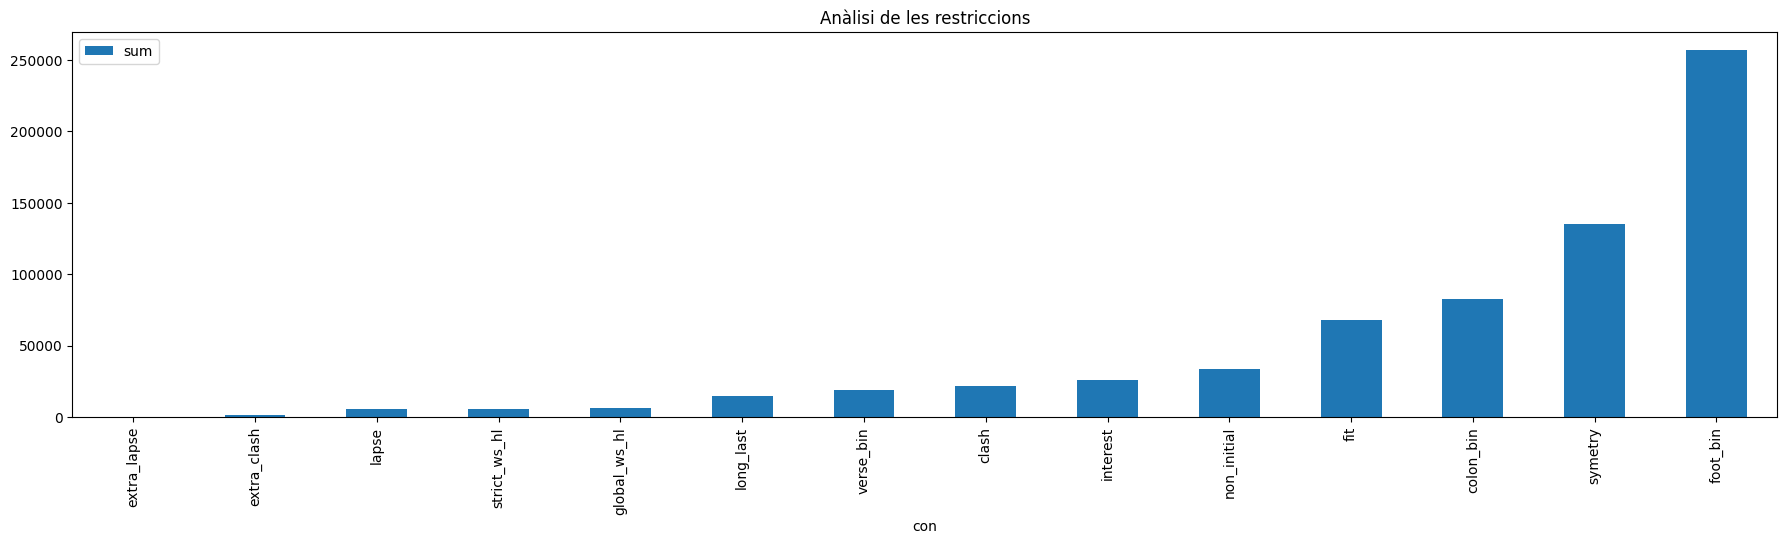

In [16]:
from AIMeRiC.data.modules.OT_constraints import OT_constraints

cons = OT_constraints('').list_constraints()
ot_analysis = pd.DataFrame({
    'con': cons,
    'sum': [ot_df[con].sum() for con in cons],
    '%': [ot_df[con].sum() / ot_df['patró comparatiu'].count() * 100 for con in cons]
    })

ot_analysis = ot_analysis.sort_values('sum', ascending=True)
ot_analysis = ot_analysis.reset_index(drop=True)
display(ot_analysis)
ot_analysis.plot(kind='bar', x='con', y='sum', title='Anàlisi de les restriccions', figsize=(22, 5))

## Restriccions rítmiques

### Clash i Extra clash

,con,sum,%
0,extra_lapse,105,0.076448
1,extra_clash,1596,1.162003
2,lapse,5378,3.915573
3,clash,21752,15.837028


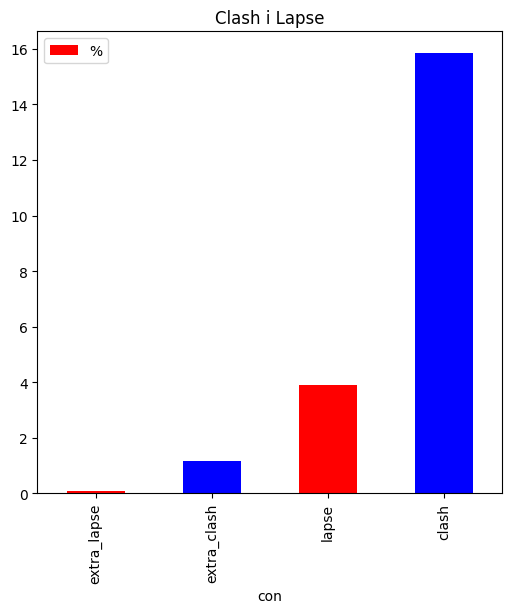

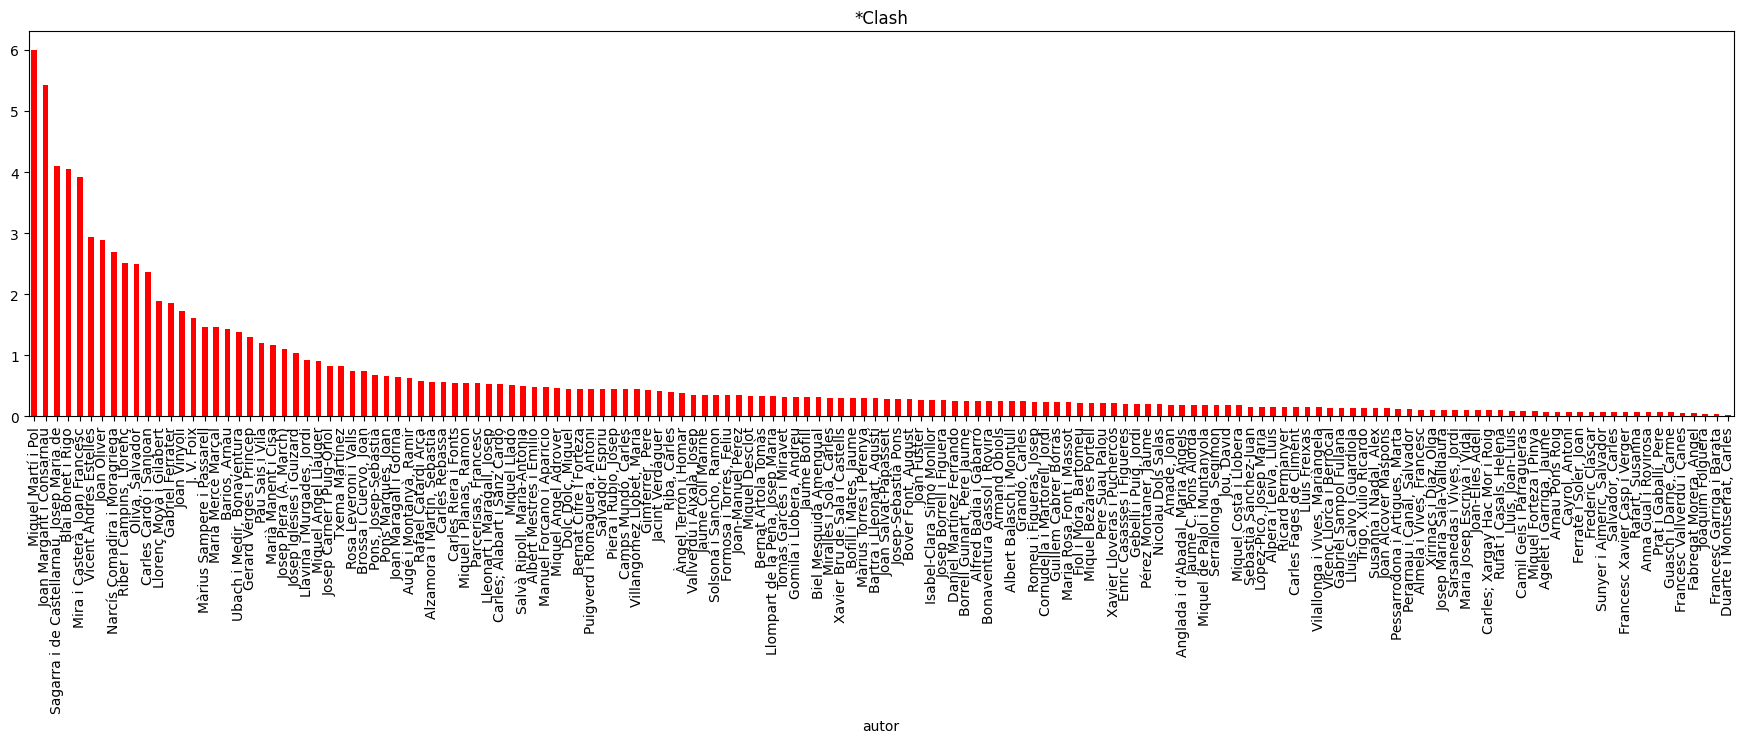

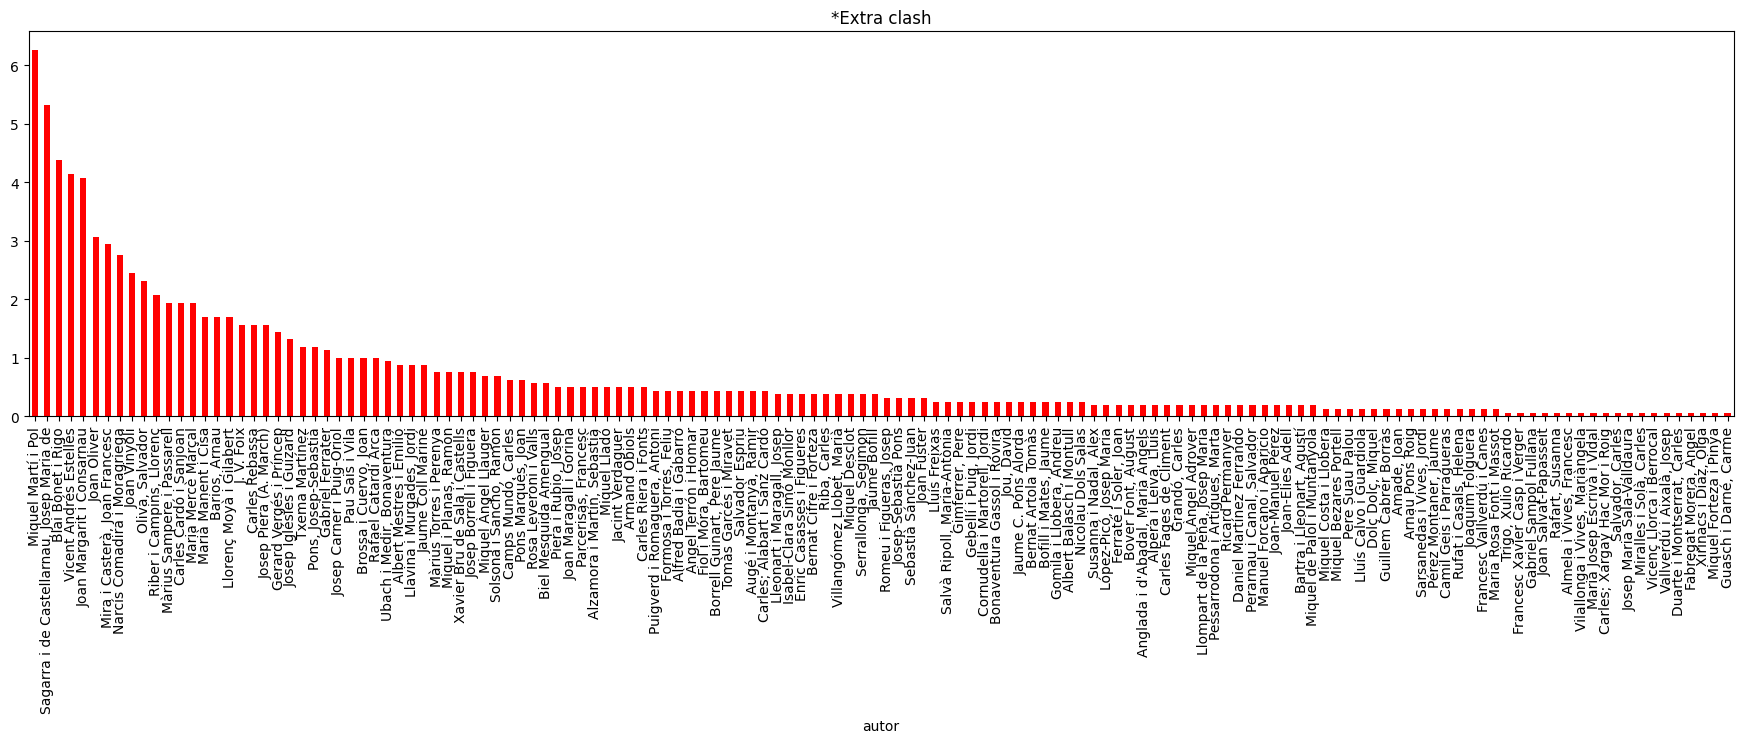

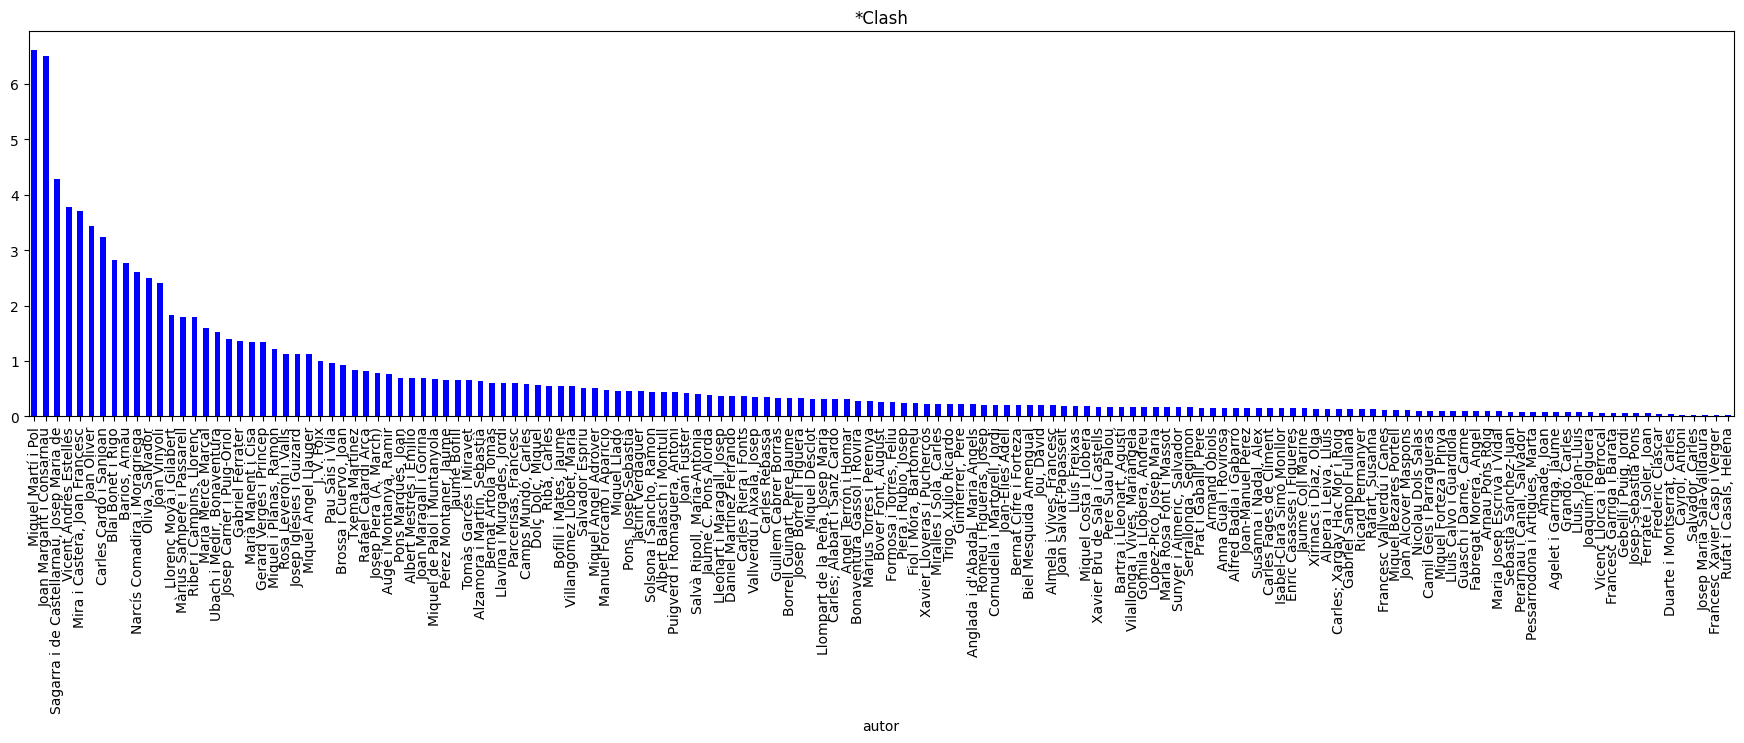

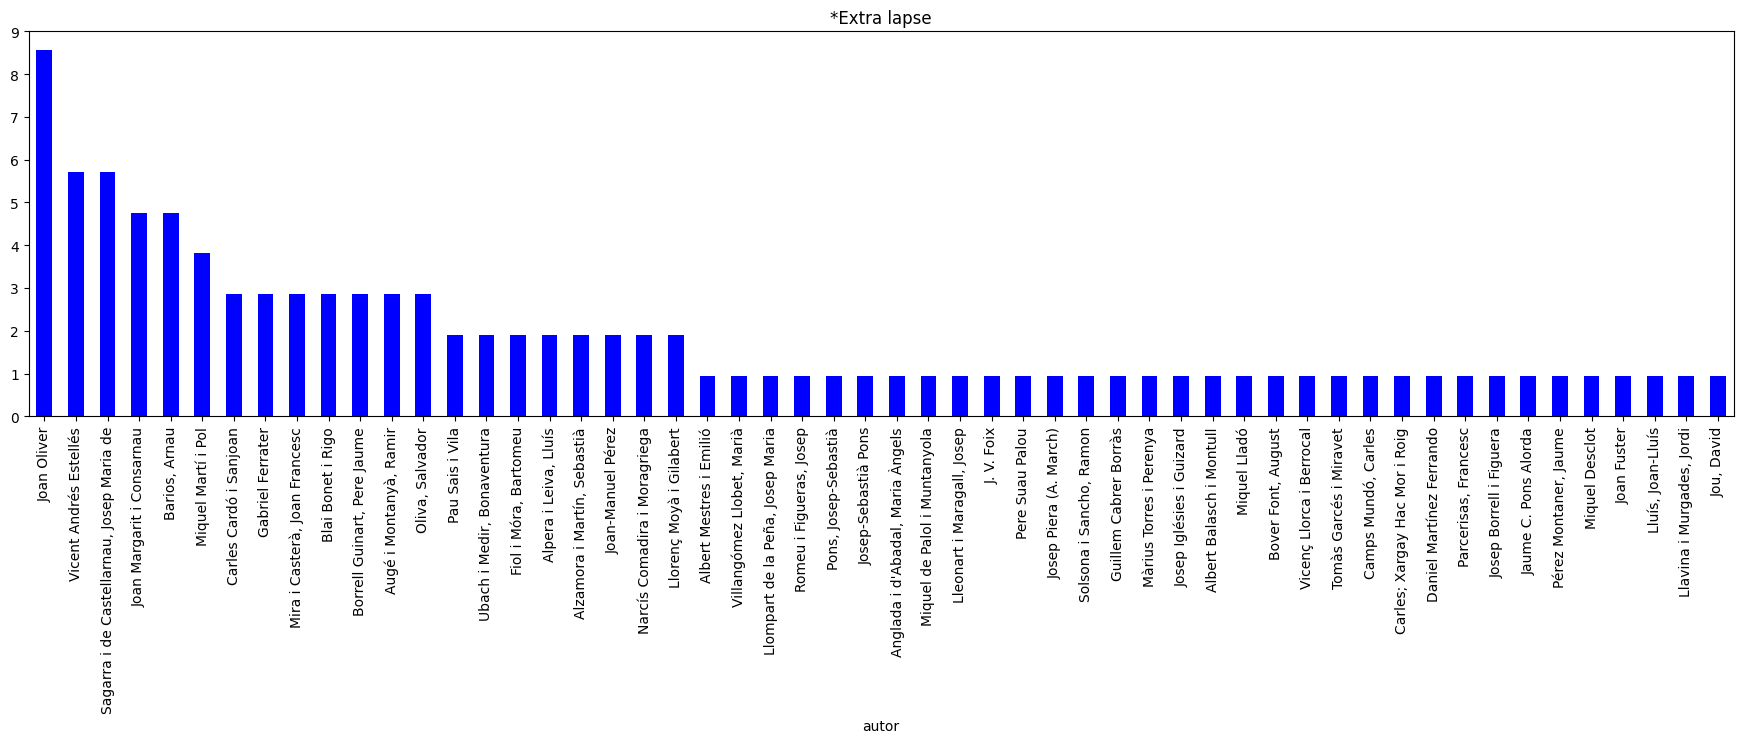

In [17]:
import matplotlib.pyplot as plt
clash_lapse_analysis = pd.DataFrame(
    {'con': ['clash', 'extra_clash', 'lapse', 'extra_lapse'],
     'sum': [
            ot_df['clash'].sum(),
            ot_df['extra_clash'].sum(),
            ot_df['lapse'].sum(),
            ot_df['extra_lapse'].sum()
         ],
     '%': [
            ot_df['clash'].sum() / ot_df['patró comparatiu'].count() * 100,
            ot_df['extra_clash'].sum() / ot_df['patró comparatiu'].count() * 100,
            ot_df['lapse'].sum() / ot_df['patró comparatiu'].count() * 100,
            ot_df['extra_lapse'].sum() / ot_df['patró comparatiu'].count() * 100
         ]})

clash_lapse_analysis = clash_lapse_analysis.sort_values('sum', ascending=True)
clash_lapse_analysis = clash_lapse_analysis.reset_index(drop=True)
display(clash_lapse_analysis)

clash_lapse_analysis.plot(kind='bar', x='con', y='%', title='Clash i Lapse', color=['red', 'blue'], figsize=(6, 6))
plt.show()

clash = ot_df[ot_df['clash'] > 0] 
extra_clash = ot_df[ot_df['extra_clash'] > 0]
(clash['autor'].value_counts() / ot_df['clash'].sum() * 100).plot(kind='bar', title='*Clash', color='red', figsize=(22, 5))
plt.show()
(extra_clash['autor'].value_counts() / ot_df['extra_clash'].sum() * 100).plot(kind='bar', title='*Extra clash', color='red', figsize=(22, 5))
plt.show()

lapse = ot_df[ot_df['lapse'] > 0] 
extra_lapse = ot_df[ot_df['extra_lapse'] > 0]
(lapse['autor'].value_counts() / ot_df['lapse'].sum() * 100).plot(kind='bar', title='*Clash', color='blue', figsize=(22, 5))
plt.show()
(extra_lapse['autor'].value_counts() / ot_df['extra_lapse'].sum() * 100).plot(kind='bar', title='*Extra lapse', color='blue', figsize=(22, 5))
plt.show()

## Strict End Hypothesis

,con,sum,%
0,strict_ws_hl,5517,4.016775
1,global_ws_hl,6526,4.751400


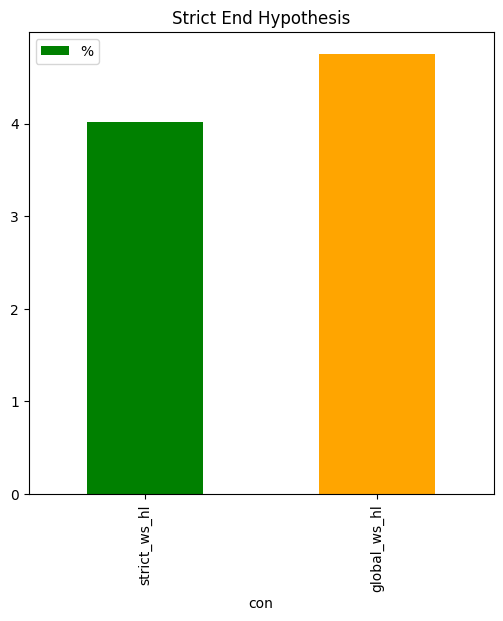

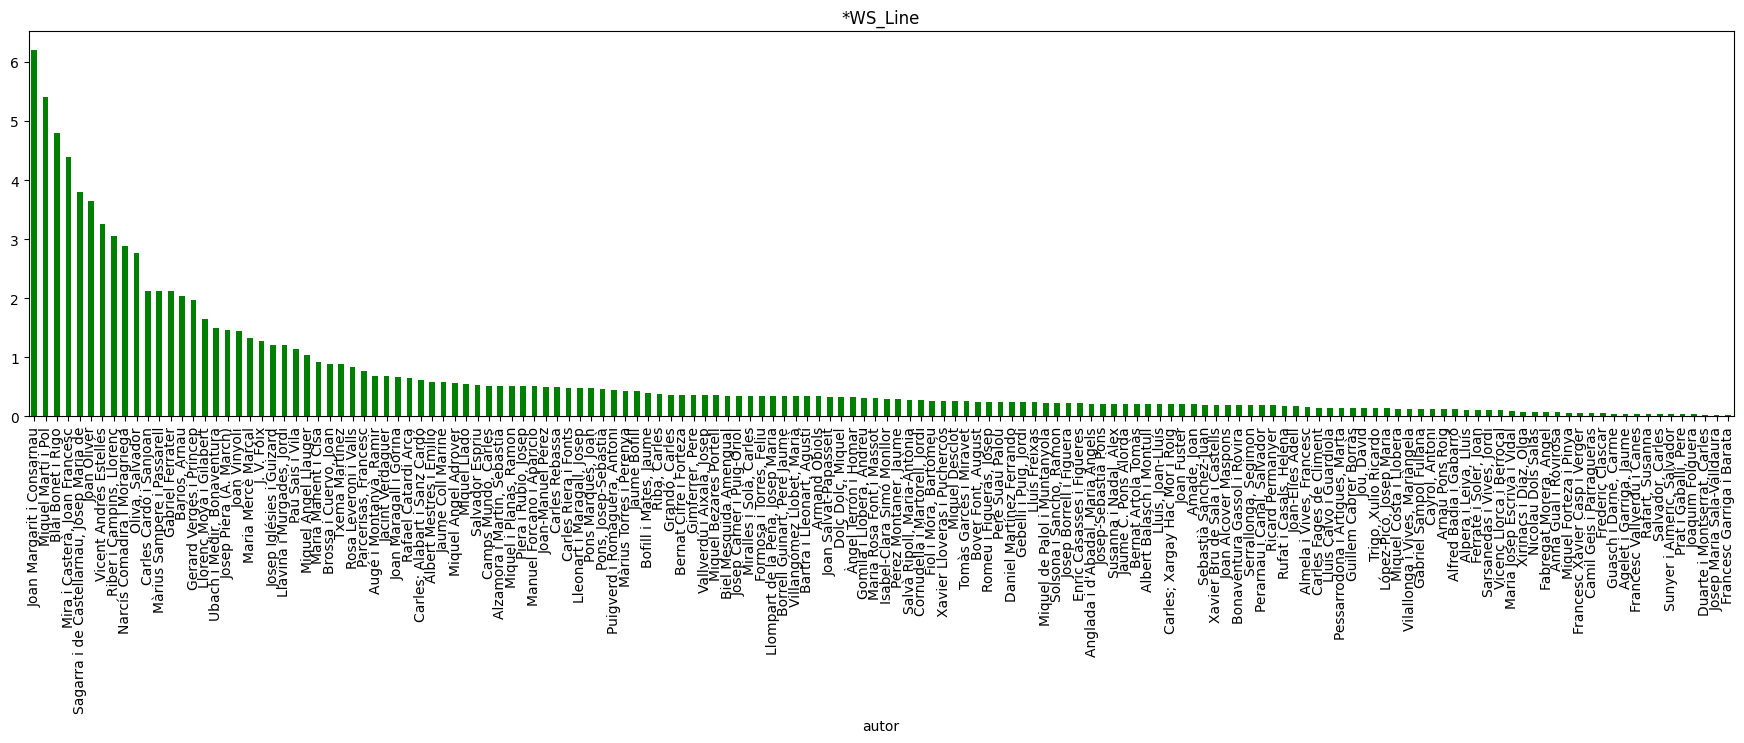

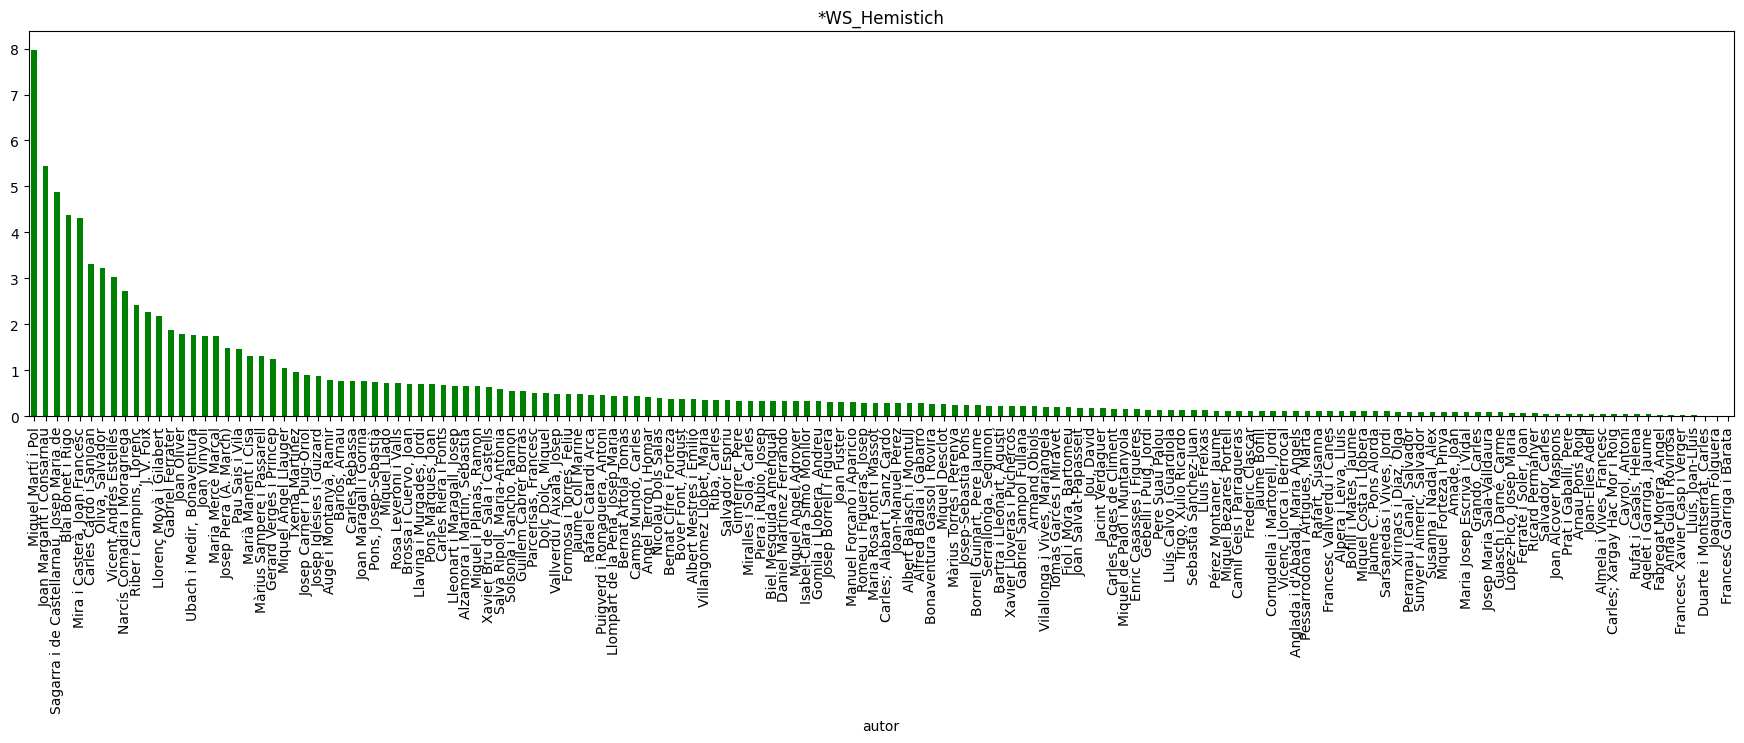

In [18]:

ws_hl_analysis = pd.DataFrame({
    'con': ['global_ws_hl', 'strict_ws_hl'],
    'sum': [
            ot_df['global_ws_hl'].sum(),
            ot_df['strict_ws_hl'].sum()
         ],
    '%': [
            ot_df['global_ws_hl'].sum() / ot_df['patró comparatiu'].count() * 100,
            ot_df['strict_ws_hl'].sum() / ot_df['patró comparatiu'].count() * 100
         ]})
ws_hl_analysis = ws_hl_analysis.sort_values('sum', ascending=True)
ws_hl_analysis = ws_hl_analysis.reset_index(drop=True)
display(ws_hl_analysis)
ws_hl_analysis.plot(kind='bar', x='con', y='%', title='Strict End Hypothesis', color=['green', 'orange'], figsize=(6, 6))


global_ws_hl = ot_df[ot_df['global_ws_hl'] > 0]
plt.figure(figsize=(22, 5))
(global_ws_hl['autor'].value_counts() / ot_df['global_ws_hl'].sum() * 100).plot(kind='bar', title='*WS_Line', color='orange')
plt.show()

strict_ws_hl = ot_df[ot_df['strict_ws_hl'] > 0]
plt.figure(figsize=(22, 5))
(strict_ws_hl['autor'].value_counts() / ot_df['strict_ws_hl'].sum() * 100).plot(kind='bar', title='*WS_Hemistich', color='green')
plt.show()

## Binarity Family

,con,sum,%
0,verse_bin,19155,13.946225
1,colon_bin,82363,59.966217
2,foot_bin,256738,186.923822


<Axes: title={'center': 'Binarity Family'}, xlabel='con'>

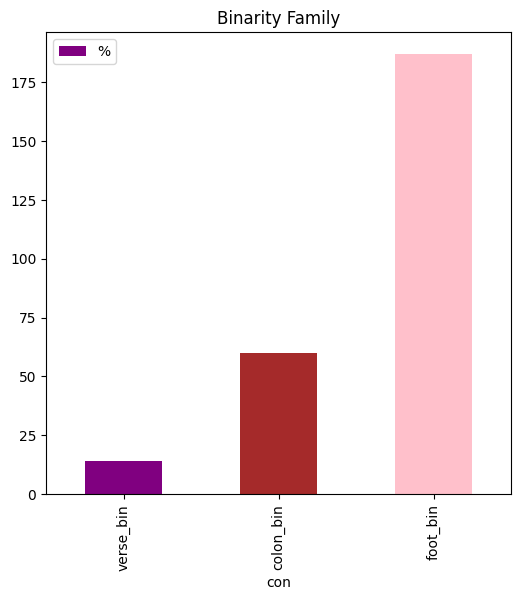

In [19]:
binarity_analysis = pd.DataFrame({
    'con': ['foot_bin', 'colon_bin', 'verse_bin'],
    'sum': [
            ot_df['foot_bin'].sum(),
            ot_df['colon_bin'].sum(),
            ot_df['verse_bin'].sum()
         ],
    '%': [
            ot_df['foot_bin'].sum() / ot_df['patró comparatiu'].count() * 100,
            ot_df['colon_bin'].sum() / ot_df['patró comparatiu'].count() * 100,
            ot_df['verse_bin'].sum() / ot_df['patró comparatiu'].count() * 100
         ]})
binarity_analysis = binarity_analysis.sort_values('sum', ascending=True)
binarity_analysis = binarity_analysis.reset_index(drop=True)
display(binarity_analysis)
binarity_analysis.plot(kind='bar', x='con', y='%', title='Binarity Family', color=['purple', 'brown', 'pink'], figsize=(6, 6))

## Long Last

,con,sum,%
0,long_last,14518,10.570153


<Axes: title={'center': '*Long Last'}, xlabel='autor'>

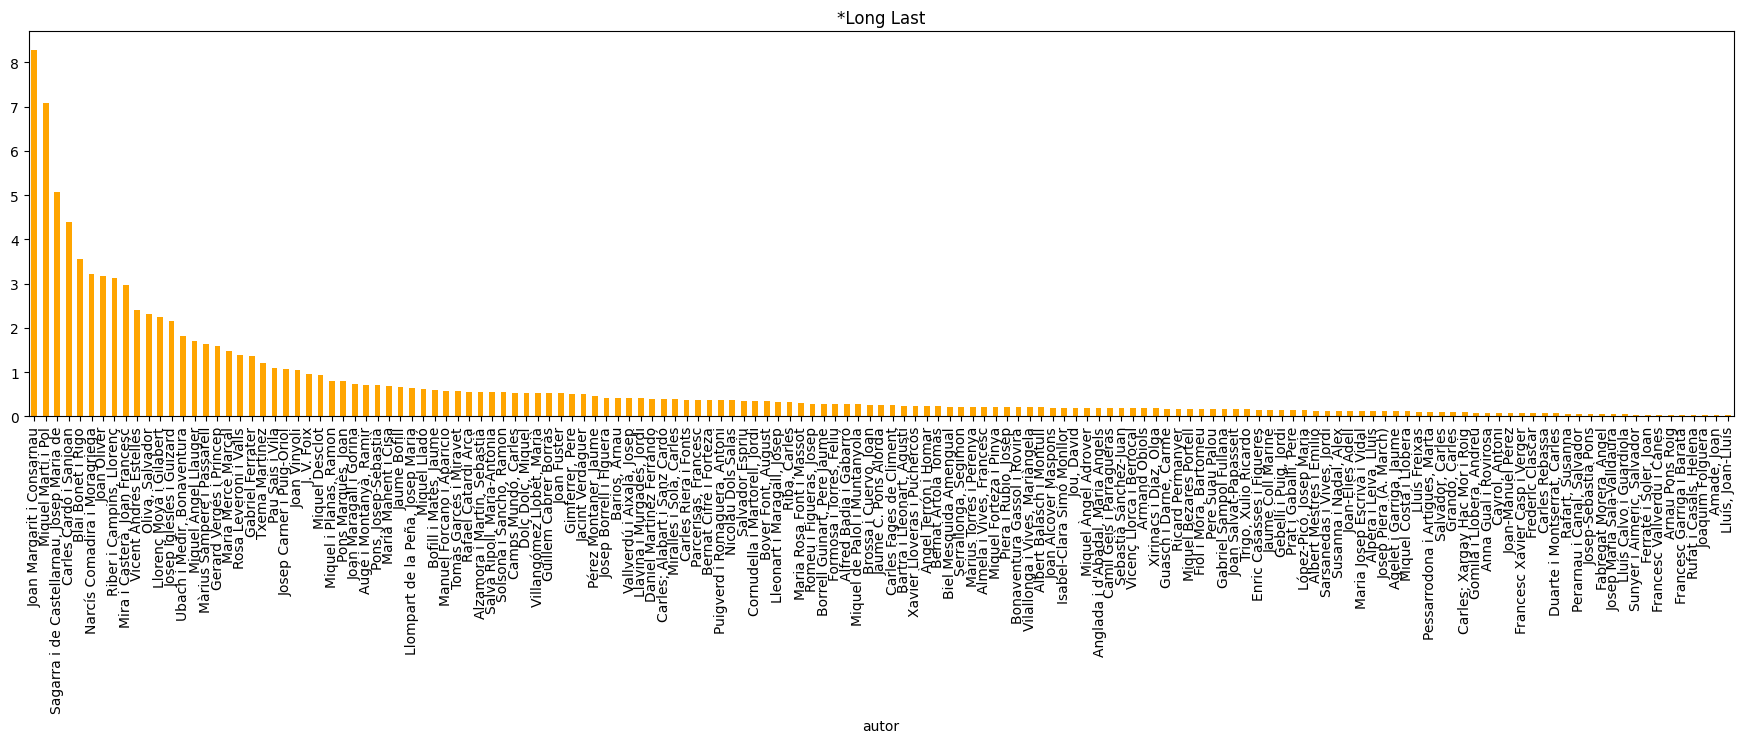

In [20]:
long_last_analysis = pd.DataFrame({
'con': ['long_last'],
'sum': [
        ot_df['long_last'].sum()
     ],
'%' : [
        ot_df['long_last'].sum() / ot_df['patró comparatiu'].count() * 100
     ]})
long_last_analysis = long_last_analysis.sort_values('sum', ascending=True)
long_last_analysis = long_last_analysis.reset_index(drop=True)
display(long_last_analysis)
long_last = ot_df[ot_df['long_last'] > 0]
(long_last['autor'].value_counts() / ot_df['long_last'].sum() * 100).plot(kind='bar', title='*Long Last', color='orange', figsize=(22, 5))

## Fit i Interest

,con,sum,%
0,interest,25603,18.640835
1,fit,68011,49.516924


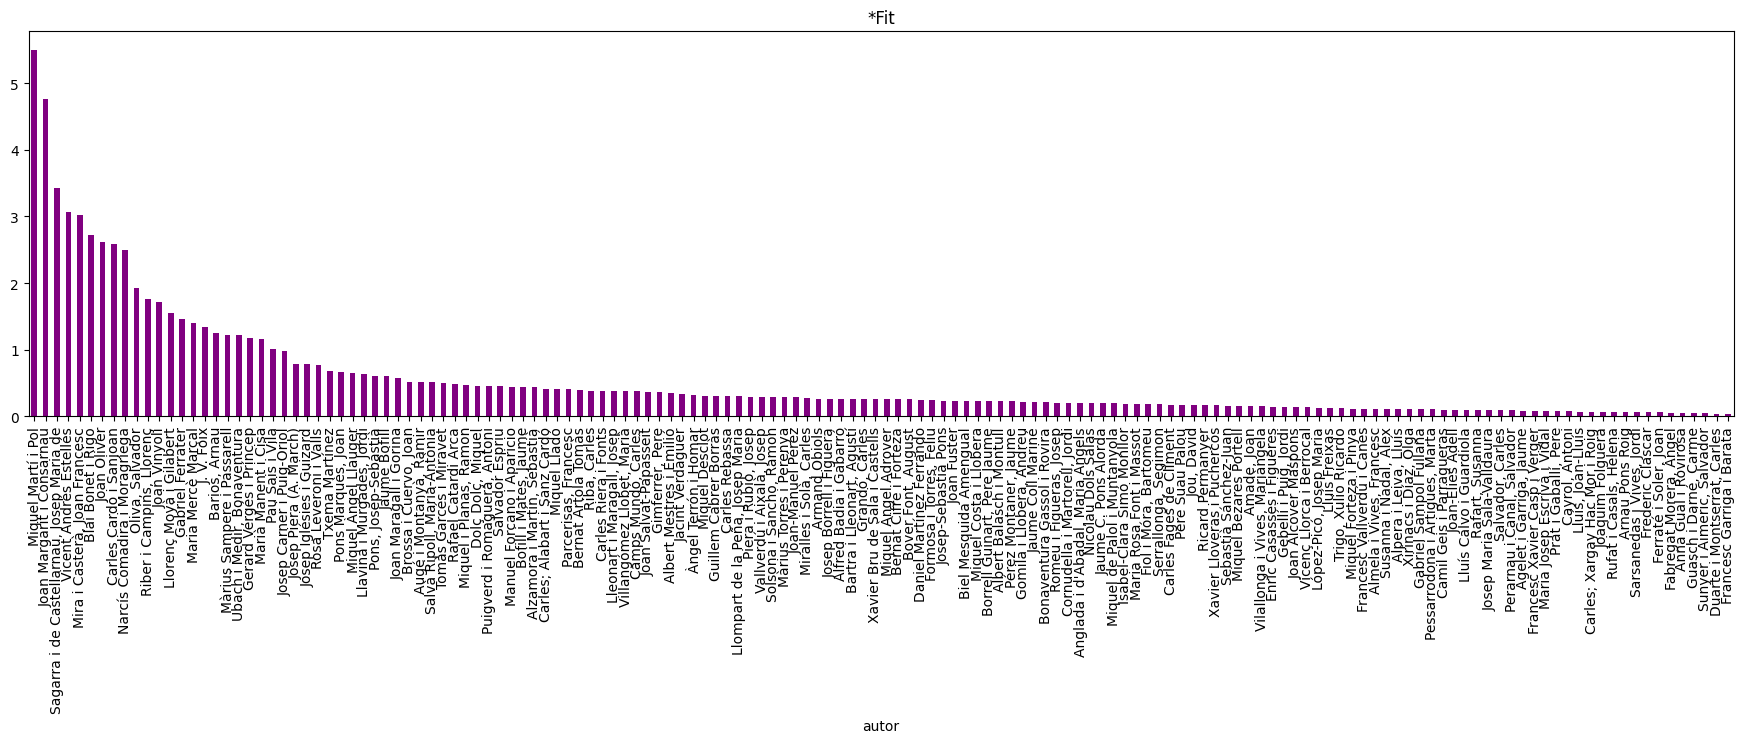

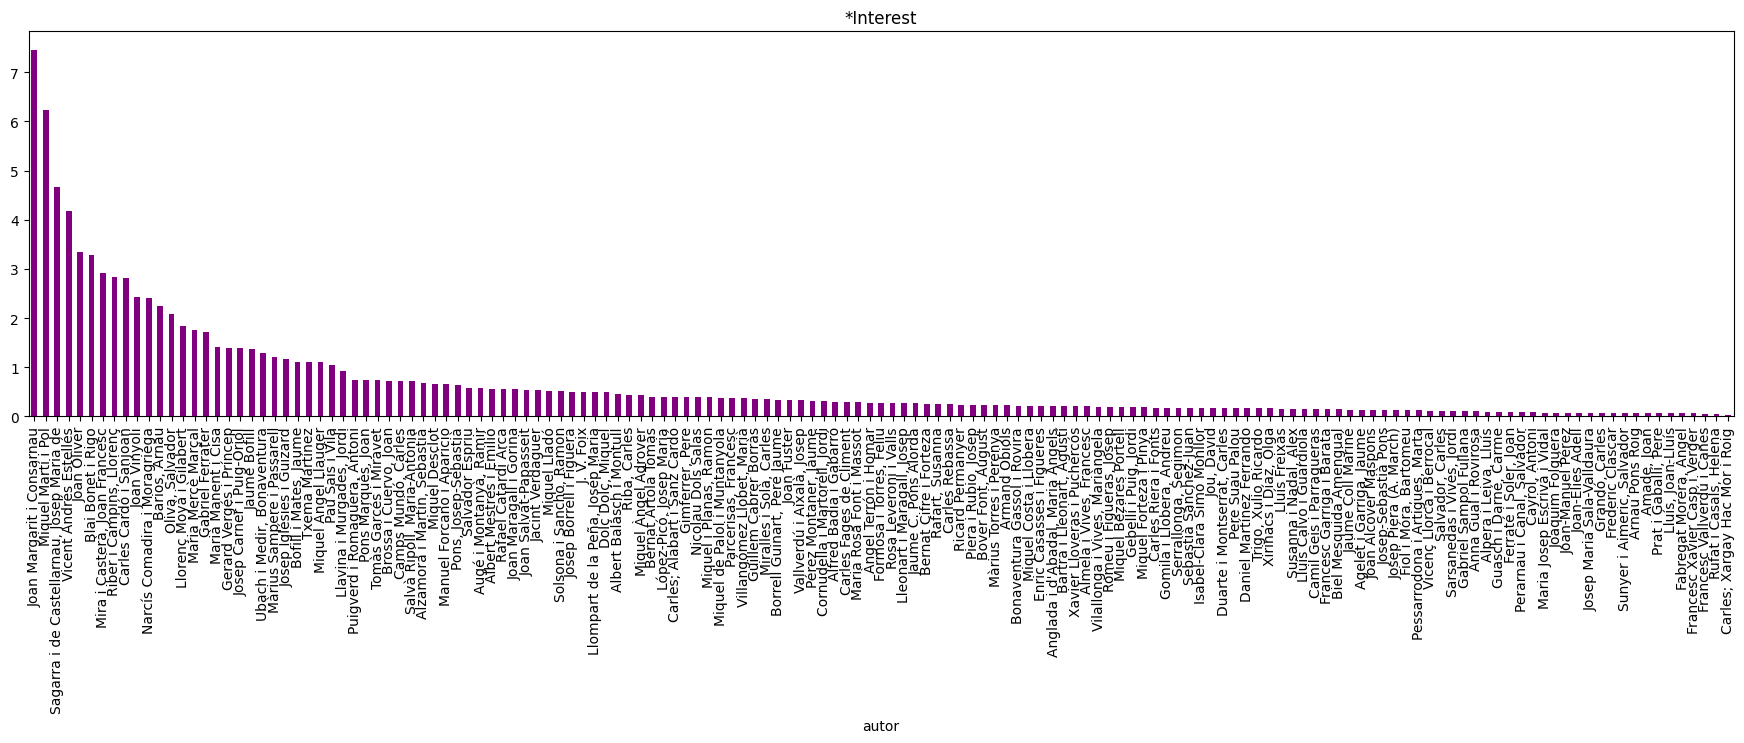

In [21]:
fit_interest_analysis = pd.DataFrame({
'con': ['fit', 'interest'],
'sum': [
        ot_df['fit'].sum(),
        ot_df['interest'].sum()
     ],
'%' : [
        ot_df['fit'].sum() / ot_df['patró comparatiu'].count() * 100,
        ot_df['interest'].sum() / ot_df['patró comparatiu'].count() * 100
     ]})
fit_interest_analysis = fit_interest_analysis.sort_values('sum', ascending=True)
fit_interest_analysis = fit_interest_analysis.reset_index(drop=True)
display(fit_interest_analysis)
fit = ot_df[ot_df['fit'] > 0]
interest = ot_df[ot_df['interest'] > 0]
(fit['autor'].value_counts() / ot_df['fit'].sum() * 100).plot(kind='bar', title='*Fit', color='purple', figsize=(22, 5))
plt.show()
(interest['autor'].value_counts() / ot_df['interest'].sum() * 100).plot(kind='bar', title='*Interest', color='pink', figsize=(22, 5))
plt.show()